### Exploration for Cleaning Project 1 data

> In this notebook we're gonna explore methods for treating missing values in the dataset and class imbalanceprepare the BRFSS data before applying the regression methods from `implementations.py`.
> The raw CSV files are kept unchanged and every transformation is fitted on the training data only.

Goals :
- load the train and test files with NumPy
- inspect missing values and the target balance
- replace empty values and BRFSS non-response codes
- remove the identifier column
- impute and standardize using training statistics only
- save clean arrays that can be used by the project code

In [72]:
import numpy as np
import matplotlib.pyplot as plt

In [73]:
import os
import numpy as np

DATA_DIR = 'dataset'
X_TRAIN_PATH = os.path.join(DATA_DIR, 'x_train.csv')
Y_TRAIN_PATH = os.path.join(DATA_DIR, 'y_train.csv')
X_TEST_PATH = os.path.join(DATA_DIR, 'x_test.csv')

np.set_printoptions(suppress=True, linewidth=120)

In [74]:
x_train_raw = np.genfromtxt(
    X_TRAIN_PATH,
    delimiter=',',
    dtype=float,
    names=True,
    missing_values='',
    filling_values=np.nan,
    autostrip=True,
)
y_train_raw = np.genfromtxt(
    Y_TRAIN_PATH,
    delimiter=',',
    dtype=float,
    names=True,
    missing_values='',
    filling_values=np.nan,
    autostrip=True,
)
x_test_raw = np.genfromtxt(
    X_TEST_PATH,
    delimiter=',',
    dtype=float,
    names=True,
    missing_values='',
    filling_values=np.nan,
    autostrip=True,
)

feature_names = np.array(x_train_raw.dtype.names)
target_name = y_train_raw.dtype.names[1]

print('x_train shape:', x_train_raw.shape)
print('y_train shape:', y_train_raw.shape)
print('x_test shape:', x_test_raw.shape)
print('number of features:', len(feature_names))
print('first feature names:', feature_names[:12])

x_train shape: (328135,)
y_train shape: (328135,)
x_test shape: (109379,)
number of features: 322
first feature names: ['Id' '_STATE' 'FMONTH' 'IDATE' 'IMONTH' 'IDAY' 'IYEAR' 'DISPCODE' 'SEQNO' '_PSU' 'CTELENUM' 'PVTRESD1']


In [75]:
target_values = y_train_raw[target_name].astype(float)
unique_targets, target_counts = np.unique(target_values, return_counts=True)

print('target values:', unique_targets)
print('target counts:', target_counts)
print('positive class proportion:', np.mean(target_values == 1))

assert np.all(np.isin(unique_targets, [-1, 1]))
assert len(target_values) == len(x_train_raw)

target values: [-1.  1.]
target counts: [299160  28975]
positive class proportion: 0.08830207079403295


In [76]:
protected_columns = {
    'Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR',
    'DISPCODE', 'SEQNO', '_PSU'
}
small_missing_codes = {7.0, 9.0}
large_missing_codes = {77.0, 99.0, 777.0, 999.0, 7777.0, 9999.0, 99999.0}

# Columns where the generic rule is wrong (checked in the BRFSS codebook).
# The listed codes are the ONLY ones treated as "don't know / refused" for that column.
missing_code_overrides = {
    'EMPLOY1': {9.0},              # 7 = "retired" is a real answer
    '_RACE': {9.0},                # 7 = "multiracial, non-Hispanic" is a real answer
    'PHYSHLTH': {77.0, 99.0},      # 7 / 9 days are real values
    'MENTHLTH': {77.0, 99.0},
    '_AGE80': set(),               # ages 77, 79... are real ages (no codes, blanks only)
    '_BMI5': set(),                # calculated variables: missing is already blank
    '_FRUTSUM': set(),
    '_VEGESUM': set(),
}
# Codes that mean "none" and must become 0 (88 = "no days" for PHYSHLTH/MENTHLTH)
zero_codes = {'PHYSHLTH': 88.0, 'MENTHLTH': 88.0}


def missing_codes_for(column_name, train_column):
    """Codes treated as missing for one column, decided from the TRAIN column only."""
    if column_name in missing_code_overrides:
        return missing_code_overrides[column_name]
    if column_name in protected_columns:
        return large_missing_codes
    # 7 / 9 are only missing codes for single-digit answers (1..9);
    # for wider columns (counts, days, measurements) they are real values
    has_values = np.any(~np.isnan(train_column))
    max_value = np.nanmax(train_column) if has_values else 0
    return large_missing_codes | (small_missing_codes if max_value <= 9 else set())


column_missing_codes = {
    name: missing_codes_for(name, x_train_raw[name].astype(float)) for name in feature_names
}


def convert_raw_features(raw_data, names):
    numeric_data = np.full((len(raw_data), len(names)), np.nan, dtype=float)

    for column_index, column_name in enumerate(names):
        column = raw_data[column_name].astype(float).copy()   # blanks are already NaN
        column[np.isin(column, list(column_missing_codes[column_name]))] = np.nan
        if column_name in zero_codes:
            column[column == zero_codes[column_name]] = 0.0
        numeric_data[:, column_index] = column

    return numeric_data


x_train_with_missing = convert_raw_features(x_train_raw, feature_names)
x_test_with_missing = convert_raw_features(x_test_raw, feature_names)

missing_counts = np.sum(np.isnan(x_train_with_missing), axis=0)
print('total missing training values:', int(np.sum(missing_counts)))
print('columns with the most missing values:')
for index in np.argsort(missing_counts)[-10:][::-1]:
    print(feature_names[index], int(missing_counts[index]))

total missing training values: 48762012
columns with the most missing values:
COLGHOUS 328103
LADULT 328103
PCDMDECN 327956
ASERVIST 327907
ASDRVIST 327907
ASNOSLEP 327803
ASACTLIM 327677
ASYMPTOM 327665
ASTHMED3 327663
ASINHALR 327659


> The main idea behind this notebook is to explore features of this dataset to be then able to deal with missing values (choose features to drop f.ex if ratio of missing values is too high or those features dont give any additional value..). Then for those remaining features we need to find the way how to treat them... (differently for cathegorical or numerical values... if its skewed or not mode, median or mean....)
> Then we need to check if there is a class imbalance and if yes... we need to find the way how to deal with it.

In [77]:
### exploration of features:
###### - proportion of missing values 
###### - skewness to check probably
###### - GOAL IS TO CHOOSE THE BEST TEQCHNIQUE TO FILL THEM OR JUST TROP THEM...

def feature_missingvalues(raw_data, names):
    """Function to explore missing values per feature in the dataset

    RETURN:
        values (np.array of shape (n_features, 2)):
            column 0 = nb of non-missing values of the feature
            column 1 = nb of missing values of the feature
        ratio (np.array of shape (n_features,)):
            proportion of missing values of the feature (between 0 and 1)
    """
    n_rows = len(raw_data)
    values = np.zeros((len(names), 2), dtype=int)

    for column_index, column_name in enumerate(names):
        if raw_data.dtype.names is not None:
            column = raw_data[column_name].astype(float)
        else:
            column = raw_data[:, column_index]

        nb_missing = int(np.sum(np.isnan(column)))
        values[column_index, 0] = n_rows - nb_missing
        values[column_index, 1] = nb_missing

    ratio = values[:, 1] / n_rows

    return values, ratio


> Here we explore the ratio and the amount of missing vales per feature.

In [78]:
values, ratio = feature_missingvalues(x_train_with_missing, feature_names)

order = np.argsort(ratio)[::-1]
#for index in order[:20]:
for index in order:
    print(f'{feature_names[index]:<12} non-missing={values[index, 0]:>7}  '
          f'missing={values[index, 1]:>7}  ratio={ratio[index]:.2%}')

for threshold in [0.3, 0.5, 0.7, 0.9]:
    print(f'features with > {threshold:.0%} missing:', int(np.sum(ratio > threshold)))


COLGHOUS     non-missing=     32  missing= 328103  ratio=99.99%
LADULT       non-missing=     32  missing= 328103  ratio=99.99%
PCDMDECN     non-missing=    179  missing= 327956  ratio=99.95%
ASERVIST     non-missing=    228  missing= 327907  ratio=99.93%
ASDRVIST     non-missing=    228  missing= 327907  ratio=99.93%
ASNOSLEP     non-missing=    332  missing= 327803  ratio=99.90%
ASACTLIM     non-missing=    458  missing= 327677  ratio=99.86%
ASYMPTOM     non-missing=    470  missing= 327665  ratio=99.86%
ASTHMED3     non-missing=    472  missing= 327663  ratio=99.86%
ASINHALR     non-missing=    476  missing= 327659  ratio=99.85%
ASATTACK     non-missing=    481  missing= 327654  ratio=99.85%
ASRCHKUP     non-missing=    486  missing= 327649  ratio=99.85%
STREHAB1     non-missing=    515  missing= 327620  ratio=99.84%
PCPSADE1     non-missing=    592  missing= 327543  ratio=99.82%
HAREHAB1     non-missing=    758  missing= 327377  ratio=99.77%
ASTHMAGE     non-missing=    776  missin

> Here in this part we drop all selected features... -> for more info abt selection of those features see: upadates/features_to_drop.md

In [79]:
features_to_drop = [
    # batch 1
    "COLGHOUS", "LADULT", "PCDMDECN", "ASERVIST", "ASDRVIST", "ASNOSLEP", "ASACTLIM", "ASYMPTOM",
    "ASTHMED3", "ASINHALR", "ASATTACK", "ASRCHKUP", "STREHAB1", "VINOCRE2", "PCPSADE1", "HAREHAB1",
    "ASTHMAGE", "CCLGHOUS", "HPVADSHT", "VIEYEXM2", "VIINSUR2", "VIMACDG2", "VIPRFVS2", "VIGLUMA2",
    "PSATIME", "PCPSARS1",
    # batch 2
    "CDHELP", "LENGEXAM", "RDUCSTRK", "RDUCHART", "RLIVPAIN", "PROFEXAM", "PCPSADI1", "PSATEST1",
    "PCPSAAD2", "PCPSARE1", "CASTHNO2", "HPLSTTST", "HPVADVC2", "CDHOUSE", "CDSOCIAL", "CDDISCUS",
    "CDASSIST", "NUMPHON2", "ASPUNSAF", "HPVTEST", "HOWLONG", "CVDASPRN", "ADPLEASR", "ADENERGY",
    "LSTBLDS3", "ARTHEXER", "ADSLEEP", "ARTHWGT", "ADEAT1", "ARTTODAY", "ARTHEDU", "ADMOVE", "ADDOWN",
    "ADTHINK", "ADFAIL", "EMTSUPRT", "LSATISFY", "ADANXEV", "MISTMNT", "LASTPAP2", "CRGVREL1",
    "CRGVPRB1", "HADHYST2", "CRGVHRS1", "HADPAP2", "HADMAM", "CRGVMST2", "CRGVLNG1", "CRGVHOUS",
    "CRGVPERS", "LONGWTCH", "SCNTLPAD", "CHKHEMO3", "SHINGLE2", "FEETCHK", "DOCTDIAB", "FEETCHK2",
    "BLDSUGAR", "EYEEXAM", "DIABEYE", "DIABEDU", "INSULIN", "SCNTPAID", "SCNTWRK1", "TETANUS",
    "SCNTLWK1", "HADSGCO1", "LASTSIG3", "LASTSMK2", "DRADVISE", "WTCHSALT", "CASTHDX2", "BLDSTOOL",
    "HADSIGM3", "DIABAGE2", "RCSGENDR", "ASTHNOW", "RCSRLTN2", "_CPRACE", "_CRACE1", "_CLLCPWT",
    "STOPSMK2", "_CHISPNC", "PREGNANT", "SCNTMNY1", "SCNTMEL1", "CRGVEXPT", "PDIABTST", "PREDIAB1",
    # batch 3
    "WHRTST10", "CAREGIV1", "HIVTSTD3", "JOINPAIN", "CIMEMLOS", "ARTHDIS2", "_PNEUMO2", "LMTJOIN3",
    "ARTHSOCL", "_FLSHOT6", "SXORIENT", "TRNSGNDR", "PAFREQ2_", "BPMEDS", "HHADULT", "SMOKDAY2",
    "IMFVPLAC", "LANDLINE", "CADULT", "CTELNUM1", "CELLFON2", "PVTRESD2", "CSTATE", "FLSHTMY2",
    "PADUR2_", "EXERHMM2", "EXEROFT2", "MAXDRNKS", "AVEDRNK2", "DRNK3GE5", "POORHLTH", "PAFREQ1_",
    "MSCODE", "CPDEMO1", "NUMHHOL2", "NUMMEN", "NUMWOMEN", "NUMADULT", "STATERES", "CTELENUM",
    "CELLFON3", "PVTRESD1", "_DUALUSE", "_DUALCOR", "PAMIN21_", "EXRACT21", "PAMIN11_", "_MINAC21",
    "METVL21_", "_HCVU651", "PAVIG21_", "_MINAC11", "ACTIN21_", "EXRACT11", "PAVIG11_", "PADUR1_",
    "EXERHMM1", "PA1MIN_", "METVL11_", "PA1VIGM_", "EXEROFT1", "ACTIN11_", "INCOME2", "_AGEG5YR",
    "PNEUVAC3", "CHOLCHK", "TOLDHI2", "STRFREQ_", "HIVTST6", "_AIDTST3", "_PAREC1", "_PASTAE1",
    "_PA30021", "_PA300R2", "_PACAT1", "_PA150R2", "_VEGLT1", "FLUSHOT6", "STRENGTH", "_PASTRNG",
    "_FRTLT1", "_RFSEAT3", "_RFSEAT2", "SEATBELT", "VEGEDA1_", "VEGETAB1", "BEANDAY_", "FVBEANS",
    "ORNGDAY_", "FVORANG", "FTJUDA1_", "FRUITJU1", "PAMISS1_", "EXERANY2", "GRENDAY_", "FVGREEN",
    "FRUTDA1_", "_BMI5CAT", "_RFBMI5", "FRUIT1", "WEIGHT2", "WTKG3", "DROCDY3_", "DRNKANY5",
    "ALCDAY5", "HTIN4", "_LMTWRK1", "_RFSMOK3", "_MRACE1", "SMOKE100", "_LMTACT1", "_LMTSCL1",
    "HTM4", "HEIGHT3", "_PRACE1", "BLOODCHO", "_RACEG21", "_RACE_G1", "_RACEGR3", "INTERNET",
    "MAXVO2_", "FC60_", "_HISPANC", "CHILDREN", "_CASTHM1", "_ASTHMS1", "_DRDXAR1", "EDUCA",
    "_LTASTH1", "_RFHYPE5", "_RFHLTH", "_DRNKWEK", "_AGE_G", "_AGE65YR", "QSTLANG", "Id", "SEQNO",
    "IDAY", "IMONTH", "IDATE", "FMONTH", "IYEAR", "DISPCODE", "QSTVER", "_VEGETEX", "_FRUITEX",
    "_VEG23", "_FRT16", "_VEGRESP", "_FRTRESP", "_MISVEGN", "_MISFRTN", "_STRWT", "_PSU", "_STSTR",
    "_LLCPWT", "_WT2RAKE", "_RAWRAKE",
]

# optional: keep survey design columns aside first
#design = x_test_with_missing[["_LLCPWT", "_STSTR", "_PSU"]].copy()

# which columns to keep
keep_mask = ~np.isin(feature_names, features_to_drop)

x_train_kept = x_train_with_missing[:, keep_mask]
x_test_kept  = x_test_with_missing[:, keep_mask]
kept_feature_names = feature_names[keep_mask]

print(x_train_kept.shape, x_test_kept.shape)
print(kept_feature_names)

(328135, 49) (109379, 49)
['_STATE' 'GENHLTH' 'PHYSHLTH' 'MENTHLTH' 'HLTHPLN1' 'PERSDOC2' 'MEDCOST' 'CHECKUP1' 'BPHIGH4' 'CVDSTRK3' 'ASTHMA3'
 'CHCSCNCR' 'CHCOCNCR' 'CHCCOPD1' 'HAVARTH3' 'ADDEPEV2' 'CHCKIDNY' 'DIABETE3' 'SEX' 'MARITAL' 'RENTHOM1' 'VETERAN3'
 'EMPLOY1' 'QLACTLM2' 'USEEQUIP' 'BLIND' 'DECIDE' 'DIFFWALK' 'DIFFDRES' 'DIFFALON' 'USENOW3' 'VIDFCLT2' 'VIREDIF3'
 'VICTRCT4' '_CHOLCHK' '_RFCHOL' '_RACE' '_AGE80' '_BMI5' '_CHLDCNT' '_EDUCAG' '_INCOMG' '_SMOKER3' '_RFBING5'
 '_RFDRHV5' '_FRUTSUM' '_VEGESUM' '_TOTINDA' '_PAINDX1']


> Now we are left with 49 features that we need to treat to deal with missing values but for that we require to know the type of it ... its distribution etc for easy and automatic approach we develop function that help us automate this process. 

In [80]:
def detect_categorical(X, names, max_unique=15):
    """A feature is treated as categorical if all its values are whole
    numbers and it has at most `max_unique` distinct values."""
    is_cat = np.zeros(len(names), dtype=bool)
    for j in range(X.shape[1]):
        vals = X[:, j][~np.isnan(X[:, j])]
        uniq = np.unique(vals)
        all_integers = np.all(np.mod(uniq, 1) == 0)
        is_cat[j] = all_integers and len(uniq) <= max_unique
    return is_cat

is_categorical = detect_categorical(x_train_kept, kept_feature_names)

# manual fixes where the rule is wrong
force_categorical = ["_STATE"]      # ~50 state codes, but they are labels, not quantities
force_numeric = []                  # add names here if something numeric gets flagged

is_categorical[np.isin(kept_feature_names, force_categorical)] = True
is_categorical[np.isin(kept_feature_names, force_numeric)] = False

# report
for name, cat, j in zip(kept_feature_names, is_categorical, range(len(kept_feature_names))):
    vals = x_train_kept[:, j][~np.isnan(x_train_kept[:, j])]
    print(f"{name:<10} {'CATEGORICAL' if cat else 'numeric':<12} unique={len(np.unique(vals))}")

categorical_features = kept_feature_names[is_categorical]
numeric_features = kept_feature_names[~is_categorical]
print("\nCategorical:", list(categorical_features))
print("Numeric:", list(numeric_features))

_STATE     CATEGORICAL  unique=53
GENHLTH    CATEGORICAL  unique=5
PHYSHLTH   numeric      unique=31
MENTHLTH   numeric      unique=31
HLTHPLN1   CATEGORICAL  unique=2
PERSDOC2   CATEGORICAL  unique=3
MEDCOST    CATEGORICAL  unique=2
CHECKUP1   CATEGORICAL  unique=5
BPHIGH4    CATEGORICAL  unique=4
CVDSTRK3   CATEGORICAL  unique=2
ASTHMA3    CATEGORICAL  unique=2
CHCSCNCR   CATEGORICAL  unique=2
CHCOCNCR   CATEGORICAL  unique=2
CHCCOPD1   CATEGORICAL  unique=2
HAVARTH3   CATEGORICAL  unique=2
ADDEPEV2   CATEGORICAL  unique=2
CHCKIDNY   CATEGORICAL  unique=2
DIABETE3   CATEGORICAL  unique=4
SEX        CATEGORICAL  unique=2
MARITAL    CATEGORICAL  unique=6
RENTHOM1   CATEGORICAL  unique=3
VETERAN3   CATEGORICAL  unique=2
EMPLOY1    CATEGORICAL  unique=8
QLACTLM2   CATEGORICAL  unique=2
USEEQUIP   CATEGORICAL  unique=2
BLIND      CATEGORICAL  unique=2
DECIDE     CATEGORICAL  unique=2
DIFFWALK   CATEGORICAL  unique=2
DIFFDRES   CATEGORICAL  unique=2
DIFFALON   CATEGORICAL  unique=2
USENOW3

> Now we are compute code that is giving us suggestion on how we should deal with missing values for each feature. It looks and the type, its distribution of numerical values etc
>We could look at its histograms to verify its suggestion.

feature     miss%   uniq    skew  suggestion
_STATE       0.00     53    0.13  categorical -> mode or constant
GENHLTH      0.27      5    0.37  categorical -> mode or constant
PHYSHLTH     2.17     31    2.19  skewed -> median
MENTHLTH     1.63     31    2.64  skewed -> median
HLTHPLN1     0.40      2    3.29  categorical -> mode or constant
PERSDOC2     0.41      3    1.62  categorical -> mode or constant
MEDCOST      0.25      2   -2.70  categorical -> mode or constant
CHECKUP1     1.35      5    2.97  categorical -> mode or constant
BPHIGH4      0.28      4   -0.34  categorical -> mode or constant
CVDSTRK3     0.22      2   -4.64  categorical -> mode or constant
ASTHMA3      0.30      2   -2.14  categorical -> mode or constant
CHCSCNCR     0.25      2   -2.76  categorical -> mode or constant
CHCOCNCR     0.20      2   -2.69  categorical -> mode or constant
CHCCOPD1     0.47      2   -3.09  categorical -> mode or constant
HAVARTH3     0.57      2   -0.70  categorical -> mode or cons

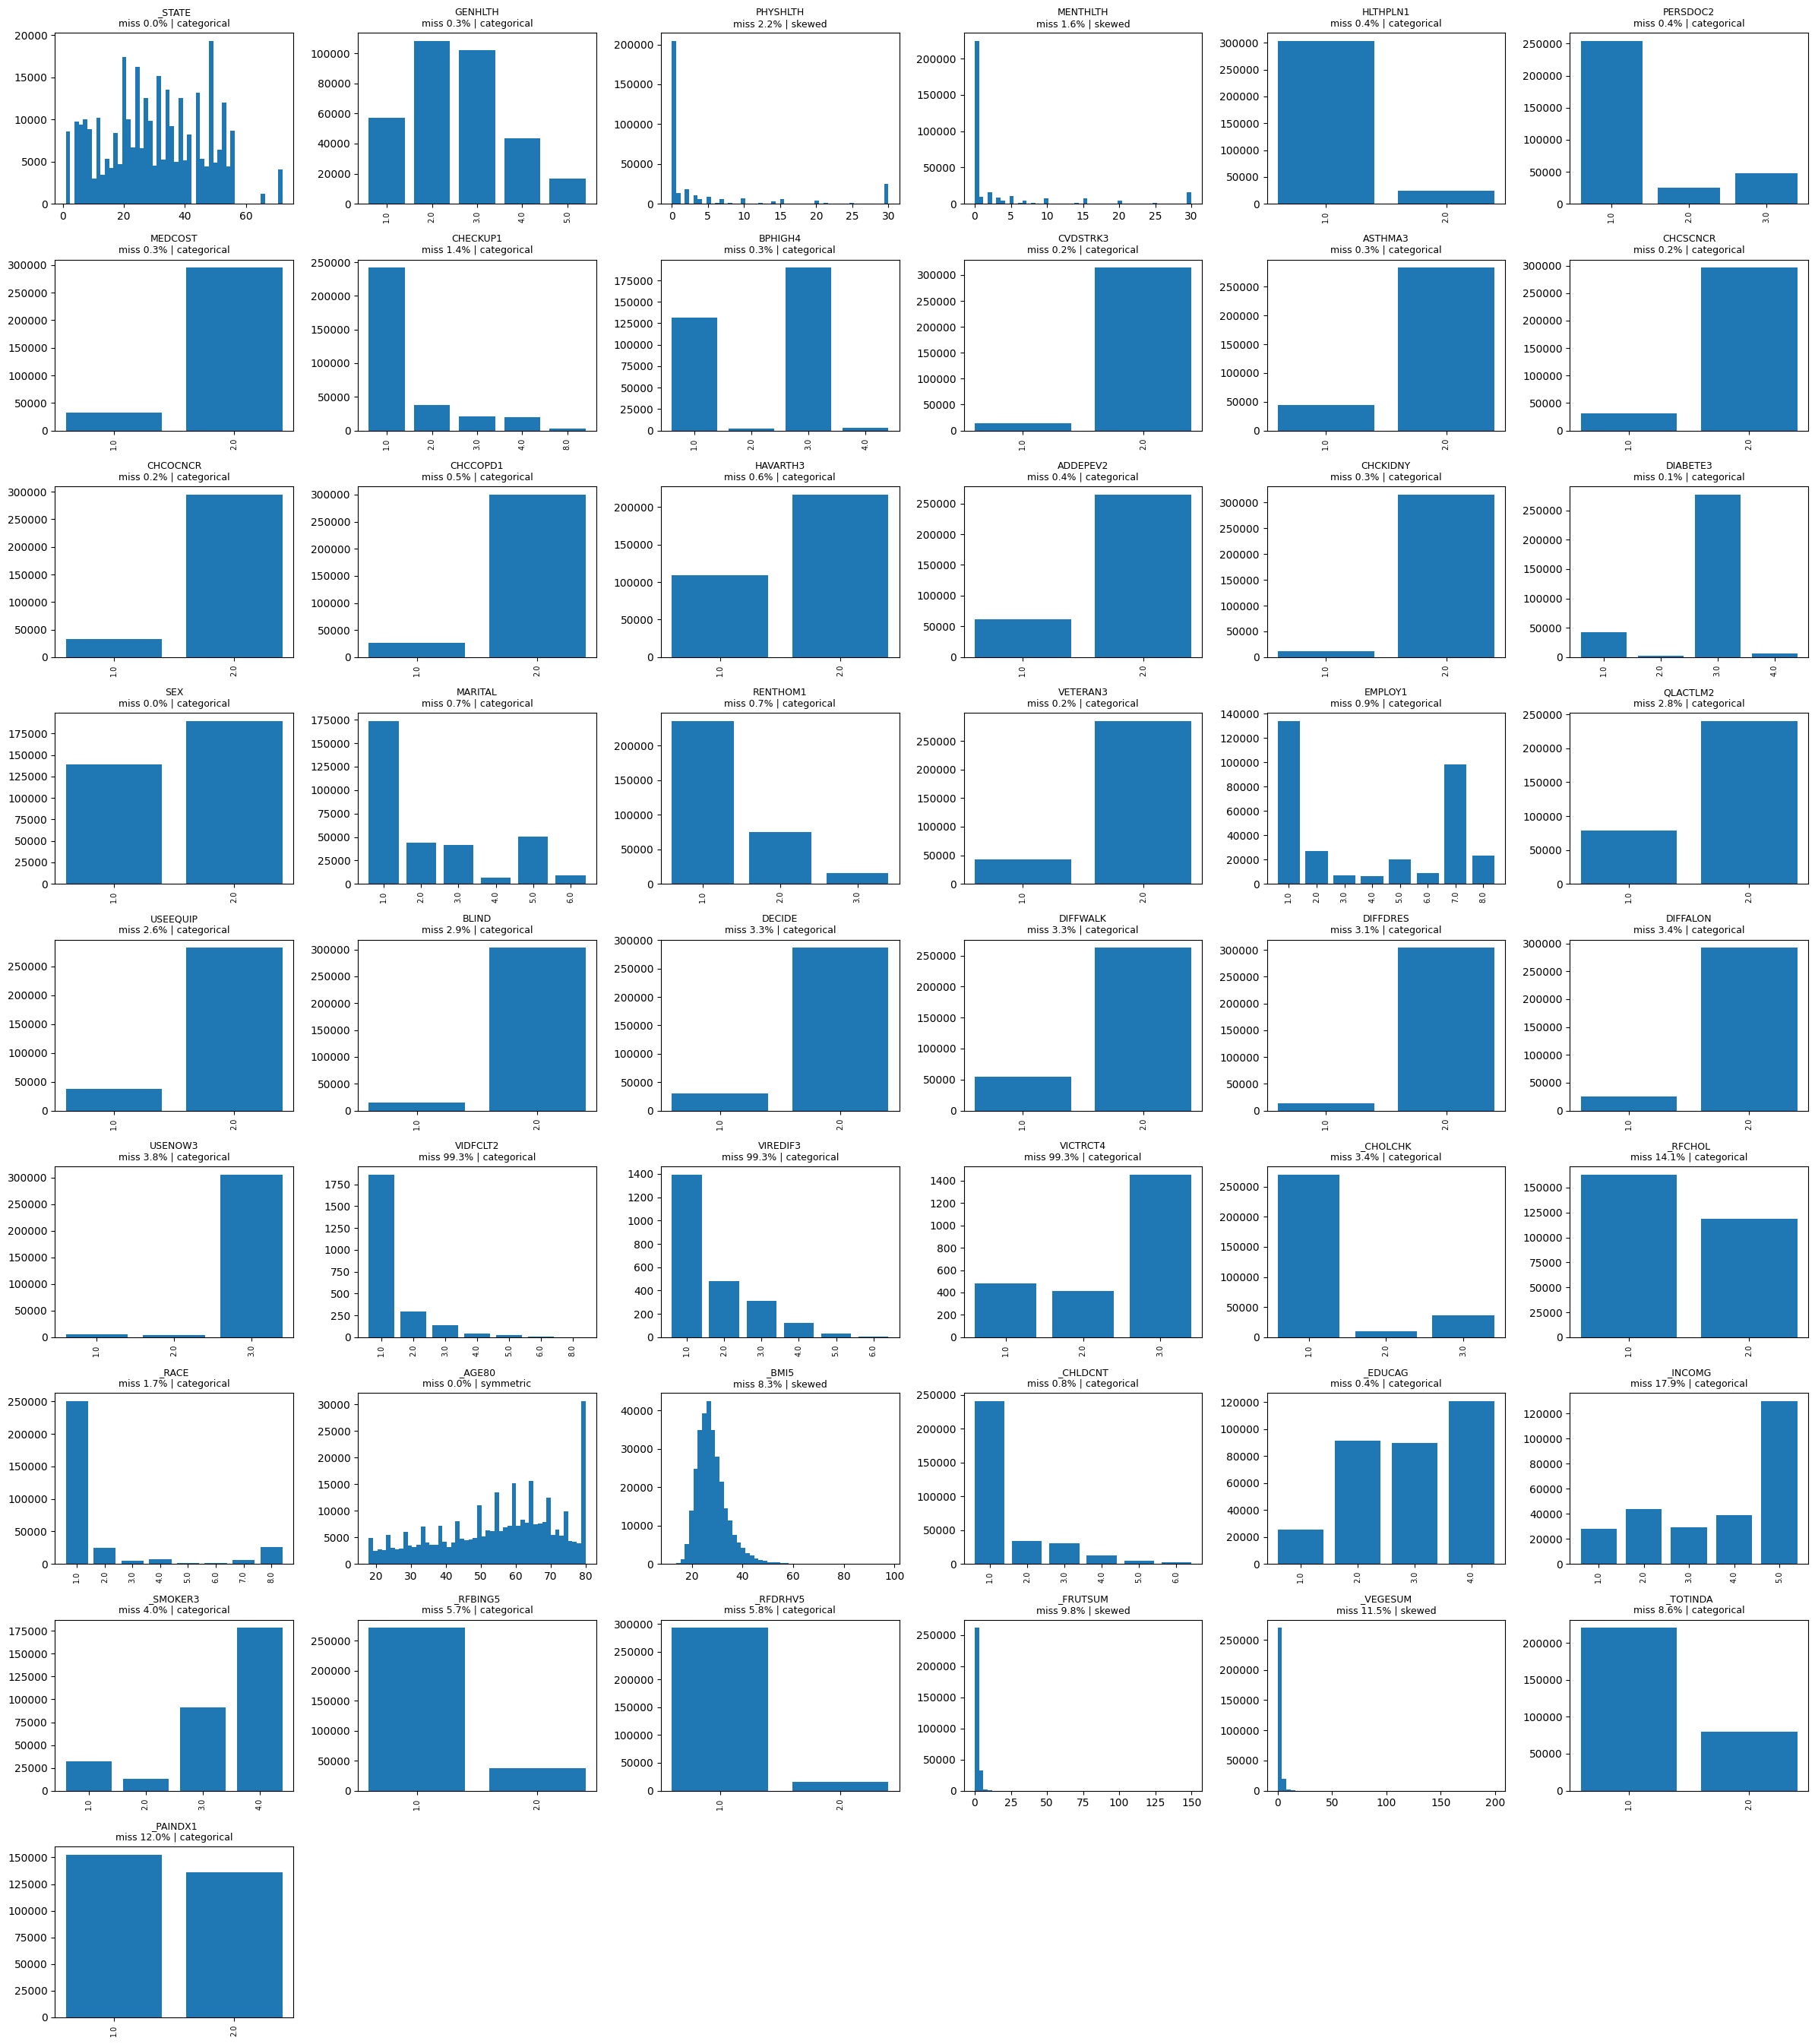

In [81]:
X = x_train_kept          # use TRAIN only to decide imputation
names = kept_feature_names

def skewness(v):
    s = v.std()
    return 0.0 if s == 0 else np.mean((v - v.mean()) ** 3) / s ** 3

summary = []
for j, name in enumerate(names):
    col = X[:, j]
    vals = col[~np.isnan(col)]
    miss = np.isnan(col).mean() * 100
    n_unique = len(np.unique(vals))
    sk = skewness(vals) if len(vals) else np.nan

    if is_categorical[j]:     # same decision as detect_categorical (+ manual fixes) above
        suggestion = "categorical -> mode or constant"
    elif abs(sk) > 1:
        suggestion = "skewed -> median"
    else:
        suggestion = "symmetric -> mean"
    summary.append((name, miss, n_unique, sk, suggestion))

# ---- printed table ----
print(f"{'feature':<10} {'miss%':>6} {'uniq':>6} {'skew':>7}  suggestion")
for name, miss, nu, sk, sug in summary:
    print(f"{name:<10} {miss:6.2f} {nu:6d} {sk:7.2f}  {sug}")

# ---- histograms ----
n_cols = 6
n_rows = int(np.ceil(len(names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = axes.ravel()

for j, (name, miss, nu, sk, sug) in enumerate(summary):
    vals = X[:, j][~np.isnan(X[:, j])]
    ax = axes[j]
    if nu <= 30:   # discrete: one bar per value
        u, c = np.unique(vals, return_counts=True)
        ax.bar(u.astype(str), c)
        ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    else:
        ax.hist(vals, bins=50)
    ax.set_title(f"{name}\nmiss {miss:.1f}% | {sug.split(' ->')[0]}", fontsize=9)

for ax in axes[len(names):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Dealing with categorical data:

> For categorical data we have 2 options to deal with missing values we could exchange them for some constant value or mode: replacing missing values with the most frequently occurring category in that column 

In [82]:

#####this is for mode version

def column_mode(col):
    vals = col[~np.isnan(col)]
    uniq, counts = np.unique(vals, return_counts=True)
    return uniq[np.argmax(counts)]

cat_idx = np.nonzero(is_categorical)[0]

# compute modes on TRAIN only
modes = {j: column_mode(x_train_kept[:, j]) for j in cat_idx}

x_train_filled = x_train_kept.copy()
x_test_filled = x_test_kept.copy()

for j in cat_idx:
    x_train_filled[np.isnan(x_train_filled[:, j]), j] = modes[j]
    x_test_filled[np.isnan(x_test_filled[:, j]), j] = modes[j]

for j in cat_idx:
    print(f"{kept_feature_names[j]:<10} mode = {modes[j]}")

#### alternative: constant (-1 = its own "missing" category after one-hot encoding).
#### Use it INSTEAD of the mode fill above (after the mode fill there are no NaNs left).
# for j in cat_idx:
#     x_train_filled[np.isnan(x_train_filled[:, j]), j] = -1
#     x_test_filled[np.isnan(x_test_filled[:, j]), j] = -1

_STATE     mode = 20.0
GENHLTH    mode = 2.0
HLTHPLN1   mode = 1.0
PERSDOC2   mode = 1.0
MEDCOST    mode = 2.0
CHECKUP1   mode = 1.0
BPHIGH4    mode = 3.0
CVDSTRK3   mode = 2.0
ASTHMA3    mode = 2.0
CHCSCNCR   mode = 2.0
CHCOCNCR   mode = 2.0
CHCCOPD1   mode = 2.0
HAVARTH3   mode = 2.0
ADDEPEV2   mode = 2.0
CHCKIDNY   mode = 2.0
DIABETE3   mode = 3.0
SEX        mode = 2.0
MARITAL    mode = 1.0
RENTHOM1   mode = 1.0
VETERAN3   mode = 2.0
EMPLOY1    mode = 1.0
QLACTLM2   mode = 2.0
USEEQUIP   mode = 2.0
BLIND      mode = 2.0
DECIDE     mode = 2.0
DIFFWALK   mode = 2.0
DIFFDRES   mode = 2.0
DIFFALON   mode = 2.0
USENOW3    mode = 3.0
VIDFCLT2   mode = 1.0
VIREDIF3   mode = 1.0
VICTRCT4   mode = 3.0
_CHOLCHK   mode = 1.0
_RFCHOL    mode = 1.0
_RACE      mode = 1.0
_CHLDCNT   mode = 1.0
_EDUCAG    mode = 4.0
_INCOMG    mode = 5.0
_SMOKER3   mode = 4.0
_RFBING5   mode = 1.0
_RFDRHV5   mode = 1.0
_TOTINDA   mode = 1.0
_PAINDX1   mode = 1.0


### Dealing with numerical data:

> For numerical features we could deal with missing values using median or mean based on the distribution of values if its skewed or symmetric etc...

In [83]:
num_idx = np.nonzero(~is_categorical)[0]

x_train_filled = x_train_filled.copy()
x_test_filled = x_test_filled.copy()

# --- 1. special codes ---
# already handled in convert_raw_features: 77/99 -> NaN and 88 -> 0 for PHYSHLTH / MENTHLTH

# --- 2. median imputation (+ optional missing indicator) ---
medians = {j: np.nanmedian(x_train_filled[:, j]) for j in num_idx}
missing_flags_train, missing_flags_test, flag_names = [], [], []

for j in num_idx:
    miss_rate = np.isnan(x_train_filled[:, j]).mean()
    if miss_rate > 0.05:   # add indicator only when missingness is substantial
        missing_flags_train.append(np.isnan(x_train_filled[:, j]).astype(float))
        missing_flags_test.append(np.isnan(x_test_filled[:, j]).astype(float))
        flag_names.append(kept_feature_names[j] + "_missing")
    x_train_filled[np.isnan(x_train_filled[:, j]), j] = medians[j]
    x_test_filled[np.isnan(x_test_filled[:, j]), j] = medians[j]

# --- 3. clip outliers at 1st / 99th percentile ---
for j in num_idx:
    lo, hi = np.percentile(x_train_filled[:, j], [1, 99])
    x_train_filled[:, j] = np.clip(x_train_filled[:, j], lo, hi)
    x_test_filled[:, j] = np.clip(x_test_filled[:, j], lo, hi)

# --- 4. standardize numeric features ---
mu = x_train_filled[:, num_idx].mean(axis=0)
sigma = x_train_filled[:, num_idx].std(axis=0)
sigma[sigma == 0] = 1   # avoid dividing by zero for constant columns
x_train_num = (x_train_filled[:, num_idx] - mu) / sigma
x_test_num = (x_test_filled[:, num_idx] - mu) / sigma

# --- 5. one-hot encode categorical features ---
# Category codes are labels, not quantities (_STATE = 53 is not "more" than _STATE = 1),
# and raw codes up to ~72 make gradient descent diverge. Each category becomes a 0/1 column.
# The first (reference) level is dropped so the columns are not collinear with the bias.
# Levels are taken from TRAIN; a level that only appears in test gets all zeros.
onehot_train, onehot_test, onehot_names = [], [], []
for j in cat_idx:
    levels = np.unique(x_train_filled[:, j])
    for level in levels[1:]:
        onehot_train.append((x_train_filled[:, j] == level).astype(float))
        onehot_test.append((x_test_filled[:, j] == level).astype(float))
        onehot_names.append(f"{kept_feature_names[j]}={level:g}")

# --- final matrices: [standardized numeric | missing indicators | one-hot categorical] ---
x_train_filled = np.column_stack([x_train_num] + missing_flags_train + onehot_train)
x_test_filled = np.column_stack([x_test_num] + missing_flags_test + onehot_test)
final_feature_names = np.concatenate([kept_feature_names[num_idx], flag_names, onehot_names])

print(x_train_filled.shape, x_test_filled.shape)
print("numeric:", len(num_idx), " missing flags:", len(flag_names), " one-hot:", len(onehot_names))
print("NaNs left:", np.isnan(x_train_filled).sum(), np.isnan(x_test_filled).sum())
print("value range:", x_train_filled.min().round(2), "to", x_train_filled.max().round(2))

(328135, 154) (109379, 154)
numeric: 6  missing flags: 3  one-hot: 145
NaNs left: 0 0
value range: -2.14 to 3.99


> After all of this we are left with train dataset that contains 0 missing values...

> We just need to deal with the huge class imbalance, that could bias our training towards majority class.

### CLASS IMBALANCE

Target: _MICHD   total samples: 328135
  class   -1:  299160  (91.17%)
  class    1:   28975  ( 8.83%)
Imbalance ratio (majority / minority): 10.3 : 1


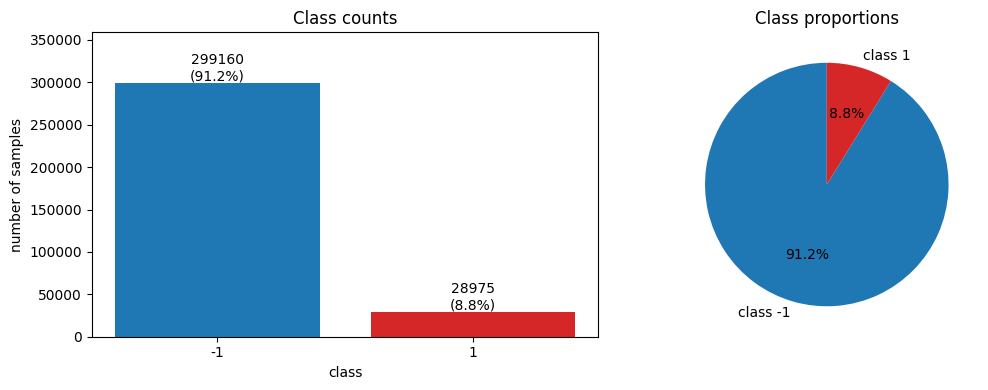

In [84]:
y = y_train_raw[target_name]
y = y[~np.isnan(y)]

classes, counts = np.unique(y, return_counts=True)
percent = counts / counts.sum() * 100

print(f"Target: {target_name}   total samples: {counts.sum()}")
for c, n, p in zip(classes, counts, percent):
    print(f"  class {c:>4g}: {n:>7d}  ({p:5.2f}%)")
print(f"Imbalance ratio (majority / minority): {counts.max() / counts.min():.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# bar chart with counts and percentages
bars = axes[0].bar([str(int(c)) for c in classes], counts, color=["tab:blue", "tab:red"][:len(classes)])
for b, n, p in zip(bars, counts, percent):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n}\n({p:.1f}%)",
                 ha="center", va="bottom", fontsize=10)
axes[0].set_title("Class counts")
axes[0].set_xlabel("class")
axes[0].set_ylabel("number of samples")
axes[0].set_ylim(0, counts.max() * 1.2)

# pie chart
axes[1].pie(counts, labels=[f"class {int(c)}" for c in classes], autopct="%1.1f%%",
            colors=["tab:blue", "tab:red"][:len(classes)], startangle=90)
axes[1].set_title("Class proportions")

plt.tight_layout()
plt.show()

In [85]:
##### HOW TO DEAL WITH CLASS IMBALANCE? SMOTE?... apply after treatemnt of missing values?

> Do we need to deal with class imbalance or we just accept the fact that in this medical case its understendable that we have much less cases with heartdisease and just dont look at accuracy rather judge only F1 score? - To answer this question we could read this article that talks about class imbalance in medical data and propose some solutions: https://pmc.ncbi.nlm.nih.gov/articles/PMC5987310/
> The most interesting part i think is this citation: Specifically, logistic regression combined with the synthetic minority oversampling technique (SMOTE) produces the best detection results, with a significant 45.3% increase in recall (recall = 75.7%) compared with pure logistic regression (recall = 52.1%).
(source: https://pmc.ncbi.nlm.nih.gov/articles/PMC5987310/)

> Then to have more info on the approach that we could use to deal with it i found this: https://medium.com/data-science/class-imbalance-strategies-a-visual-guide-with-code-8bc8fae71e1a

> It gives us few techniques and shows us how to pick the best one using ROC curve.

### Implementation of those techniques

In [86]:
def _knn(query, data, k, exclude_self=False):
    """Indices of the k nearest neighbours (Euclidean) in `data` for each row of `query`.
    Computed in batches so memory stays manageable with ~300k rows."""
    kk = k + 1 if exclude_self else k
    data_sq = np.sum(data ** 2, axis=1)
    batch = max(1, int(2e7 // data.shape[0]))          # ~160 MB distance block
    out = np.empty((query.shape[0], kk), dtype=np.int64)
    for s in range(0, query.shape[0], batch):
        q = query[s:s + batch]
        d = np.sum(q ** 2, axis=1)[:, None] + data_sq[None, :] - 2 * q @ data.T
        idx = np.argpartition(d, kk - 1, axis=1)[:, :kk]
        rows = np.arange(idx.shape[0])[:, None]
        order = np.argsort(d[rows, idx], axis=1)
        out[s:s + batch] = idx[rows, order]
    return out[:, 1:] if exclude_self else out     # drop the point itself


def _shuffle(X, y, rng):
    p = rng.permutation(len(y))
    return X[p], y[p]


def random_undersampling(X, y, ratio=1.0, seed=42):
    """Keep all minority samples; randomly keep ratio * n_minority majority samples."""
    rng = np.random.default_rng(seed)
    min_idx, maj_idx = np.nonzero(y == 1)[0], np.nonzero(y == 0)[0]
    n_keep = min(len(maj_idx), int(len(min_idx) * ratio))
    keep = np.concatenate([min_idx, rng.choice(maj_idx, n_keep, replace=False)])
    return _shuffle(X[keep], y[keep], rng)


def random_oversampling(X, y, ratio=1.0, seed=42):
    """Duplicate random minority samples until n_minority = ratio * n_majority."""
    rng = np.random.default_rng(seed)
    min_idx, maj_idx = np.nonzero(y == 1)[0], np.nonzero(y == 0)[0]
    n_new = max(0, int(len(maj_idx) * ratio) - len(min_idx))
    extra = rng.choice(min_idx, n_new, replace=True)
    keep = np.concatenate([np.arange(len(y)), extra])
    return _shuffle(X[keep], y[keep], rng)


def smote(X, y, k=5, ratio=1.0, seed=42):
    """Create synthetic minority points on the line between a minority sample
    and one of its k nearest minority neighbours."""
    rng = np.random.default_rng(seed)
    x_min = X[y == 1]
    n_new = max(0, int(np.sum(y == 0) * ratio) - len(x_min))
    nn = _knn(x_min, x_min, k, exclude_self=True)

    base = rng.integers(0, len(x_min), n_new)
    nbr = nn[base, rng.integers(0, k, n_new)]
    gap = rng.random((n_new, 1))
    x_new = x_min[base] + gap * (x_min[nbr] - x_min[base])

    x_out = np.vstack([X, x_new])
    y_out = np.concatenate([y, np.ones(n_new, dtype=y.dtype)])
    return _shuffle(x_out, y_out, rng)


def adasyn(X, y, k=5, ratio=1.0, seed=42):
    """Like SMOTE, but generates more synthetic points around minority samples
    that are surrounded by many majority samples (the 'hard' ones)."""
    rng = np.random.default_rng(seed)
    min_idx = np.nonzero(y == 1)[0]
    x_min = X[min_idx]
    G = max(0, int(np.sum(y == 0) * ratio) - len(min_idx))

    # difficulty: fraction of majority points among k neighbours in the full data
    nn_all = _knn(x_min, X, k, exclude_self=True)
    r = np.mean(y[nn_all] == 0, axis=1)
    r = r / r.sum() if r.sum() > 0 else np.full(len(r), 1 / len(r))
    g = np.round(r * G).astype(int)                 # samples to create per point

    nn_min = _knn(x_min, x_min, k, exclude_self=True)
    base = np.repeat(np.arange(len(x_min)), g)
    nbr = nn_min[base, rng.integers(0, k, len(base))]
    gap = rng.random((len(base), 1))
    x_new = x_min[base] + gap * (x_min[nbr] - x_min[base])

    x_out = np.vstack([X, x_new])
    y_out = np.concatenate([y, np.ones(len(base), dtype=y.dtype)])
    return _shuffle(x_out, y_out, rng)


def tomek_link(X, y, seed=42):
    """Remove majority samples that form a Tomek link with a minority sample
    (two points of opposite class that are each other's nearest neighbour)."""
    rng = np.random.default_rng(seed)
    min_idx = np.nonzero(y == 1)[0]

    nn_of_min = _knn(X[min_idx], X, 1, exclude_self=True)[:, 0]
    cand = nn_of_min[y[nn_of_min] == 0]            # majority points closest to a minority point
    cand_min = min_idx[y[nn_of_min] == 0]

    nn_of_cand = _knn(X[cand], X, 1, exclude_self=True)[:, 0]
    to_remove = np.unique(cand[nn_of_cand == cand_min])   # mutual nearest neighbours

    keep = np.setdiff1d(np.arange(len(y)), to_remove)
    print(f"TomekLink: removed {len(to_remove)} majority samples")
    return _shuffle(X[keep], y[keep], rng)

train: (262508, 154) positives: 0.0883
val:   (65627, 154) positives: 0.0883
NaN in x_tr: 0  x_val: 0
y values: [0 1]


/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/2698202964.py:28: RuntimeWarning: divide by zero encountered in matmul
  p = sigmoid(xb @ w)
/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/2698202964.py:28: RuntimeWarning: overflow encountered in matmul
  p = sigmoid(xb @ w)
/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/2698202964.py:28: RuntimeWarning: invalid value encountered in matmul
  p = sigmoid(xb @ w)
/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/2698202964.py:29: RuntimeWarning: divide by zero encountered in matmul
  grad = xb.T @ (sw * (p - y)) / len(y)
/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/2698202964.py:29: RuntimeWarning: overflow encountered in matmul
  grad = xb.T @ (sw * (p - y)) / len(y)
/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/2698202964.py:29: RuntimeWarning: invalid value encountered in matmul
  grad = xb.T @ (sw * (p - y)) / len(y)
/var/folders/nr/my

NaN in w: 0  NaN in probs: 0
max |w|: 0.75  saturated probs: 0.0
Baseline       n_train= 262508  pos=0.09  AUC=0.8553  AP=0.3748  F1=0.4253  thr=0.193  (5s)
Class weights  n_train= 262508  pos=0.09  AUC=0.8566  AP=0.3747  F1=0.4238  thr=0.690  (5s)
Random under   n_train=  69540  pos=0.33  AUC=0.8566  AP=0.3760  F1=0.4249  thr=0.572  (1s)
Random over    n_train= 358992  pos=0.33  AUC=0.8568  AP=0.3762  F1=0.4252  thr=0.526  (7s)


/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/3368560560.py:10: RuntimeWarning: divide by zero encountered in matmul
  d = np.sum(q ** 2, axis=1)[:, None] + data_sq[None, :] - 2 * q @ data.T
/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/3368560560.py:10: RuntimeWarning: overflow encountered in matmul
  d = np.sum(q ** 2, axis=1)[:, None] + data_sq[None, :] - 2 * q @ data.T
/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/3368560560.py:10: RuntimeWarning: invalid value encountered in matmul
  d = np.sum(q ** 2, axis=1)[:, None] + data_sq[None, :] - 2 * q @ data.T


SMOTE          n_train= 358992  pos=0.33  AUC=0.8531  AP=0.3731  F1=0.4231  thr=0.581  (11s)
ADASYN         n_train= 354276  pos=0.32  AUC=0.8526  AP=0.3721  F1=0.4228  thr=0.550  (52s)
TomekLink: removed 3476 majority samples
Tomek links    n_train= 259032  pos=0.09  AUC=0.8552  AP=0.3745  F1=0.4243  thr=0.206  (32s)

method          ROC AUC   PR AP  best F1  precision  recall  threshold
Baseline         0.8553  0.3748   0.4253     0.3471  0.5491      0.193
Random over      0.8568  0.3762   0.4252     0.3315  0.5926      0.526
Random under     0.8566  0.3760   0.4249     0.3553  0.5284      0.572
Tomek links      0.8552  0.3745   0.4243     0.3511  0.5362      0.206
Class weights    0.8566  0.3747   0.4238     0.3303  0.5912      0.690
SMOTE            0.8531  0.3731   0.4231     0.3559  0.5217      0.581
ADASYN           0.8526  0.3721   0.4228     0.3418  0.5539      0.550


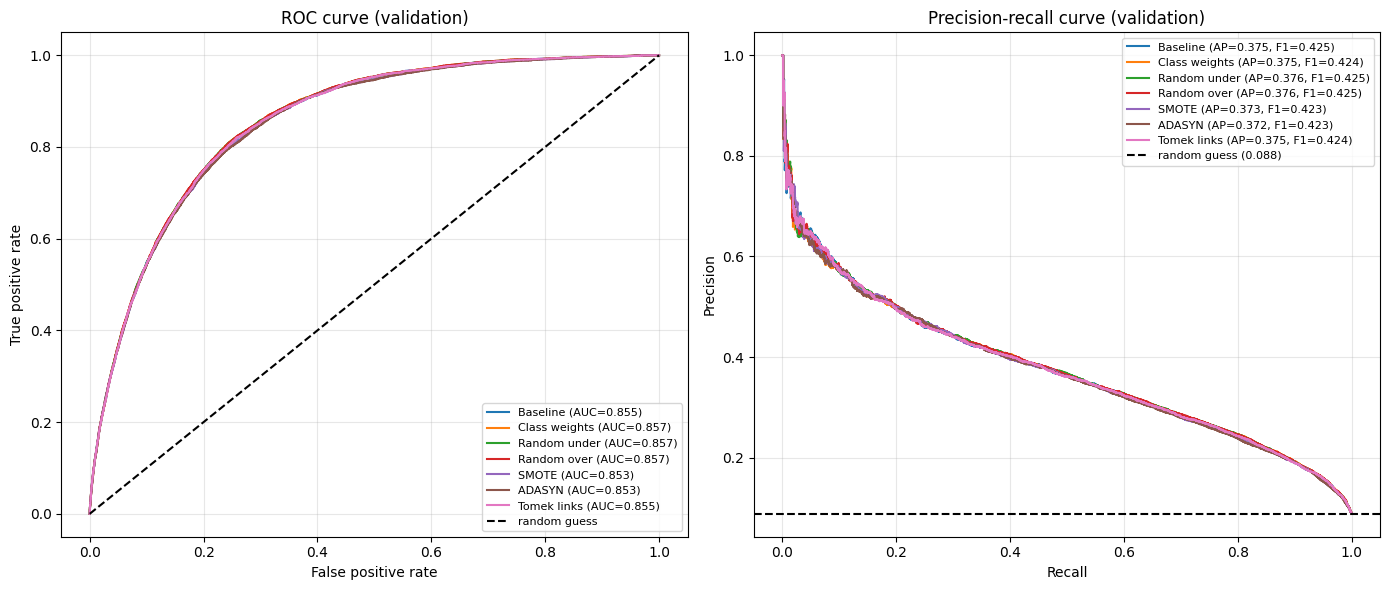

In [87]:
import time

# ---------------- data ----------------
X_all = x_train_filled                                   # cleaned, imputed, standardized, one-hot
y_all = (y_train_raw[target_name] == 1).astype(int)      # -1/1  ->  0/1

def stratified_split(X, y, val_frac=0.2, seed=42):
    rng = np.random.default_rng(seed)
    is_val = np.zeros(len(y), dtype=bool)
    for c in np.unique(y):
        idx = rng.permutation(np.nonzero(y == c)[0])
        is_val[idx[:int(len(idx) * val_frac)]] = True
    return X[~is_val], y[~is_val], X[is_val], y[is_val]

x_tr, y_tr, x_val, y_val = stratified_split(X_all, y_all)
print("train:", x_tr.shape, "positives:", y_tr.mean().round(4))
print("val:  ", x_val.shape, "positives:", y_val.mean().round(4))

# ---------------- logistic regression ----------------
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def train_logreg(X, y, sample_weight=None, lr=0.5, n_iter=500, lambda_=1e-4):
    xb = np.column_stack([np.ones(len(X)), X])
    w = np.zeros(xb.shape[1])
    sw = np.ones(len(y)) if sample_weight is None else sample_weight / sample_weight.mean()
    for _ in range(n_iter):
        p = sigmoid(xb @ w)
        grad = xb.T @ (sw * (p - y)) / len(y)
        grad[1:] += lambda_ * w[1:]                      # no penalty on the bias
        w -= lr * grad
    return w

def predict_proba(X, w):
    return sigmoid(np.column_stack([np.ones(len(X)), X]) @ w)

# ---------------- metrics ----------------
def curves(y_true, scores):
    """ROC points, PR points, and the best-F1 threshold, all from one sort.
    Samples with the SAME score are one threshold: we only keep the point after the
    last sample of each group of ties, otherwise their arbitrary order changes the AUC."""
    order = np.argsort(-scores, kind="mergesort")
    ys, ss = y_true[order], scores[order]
    last_of_group = np.r_[np.nonzero(np.diff(ss) != 0)[0], len(ss) - 1]
    tps, fps = np.cumsum(ys)[last_of_group], np.cumsum(1 - ys)[last_of_group]
    thresholds = ss[last_of_group]
    P, N = tps[-1], fps[-1]

    fpr, tpr = np.r_[0, fps / N], np.r_[0, tps / P]
    precision, recall = tps / (tps + fps), tps / P

    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    best = np.argmax(f1)
    auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)
    ap = np.sum(np.diff(np.r_[0, recall]) * precision)
    return {"fpr": fpr, "tpr": tpr, "precision": precision, "recall": recall,
            "auc": auc, "ap": ap, "f1": f1[best], "threshold": thresholds[best],
            "prec_at_best": precision[best], "rec_at_best": recall[best]}

# ---------------- methods to compare ----------------
UNDER_RATIO = 2.0   # keep 2 negatives per positive  (~33% positives)
OVER_RATIO = 0.5    # grow positives to 50% of negatives (~33% positives)

n_pos, n_neg = y_tr.sum(), len(y_tr) - y_tr.sum()

methods = {
    "Baseline":        lambda X, y: (X, y, None),
    "Class weights":   lambda X, y: (X, y, np.where(y == 1, n_neg / n_pos, 1.0)),
    "Random under":    lambda X, y: (*random_undersampling(X, y, ratio=UNDER_RATIO), None),
    "Random over":     lambda X, y: (*random_oversampling(X, y, ratio=OVER_RATIO), None),
    "SMOTE":           lambda X, y: (*smote(X, y, k=5, ratio=OVER_RATIO), None),
    "ADASYN":          lambda X, y: (*adasyn(X, y, k=5, ratio=OVER_RATIO), None),   # slow
    "Tomek links":     lambda X, y: (*tomek_link(X, y), None),                        # slow
}

# ---------------- sanity check ----------------
print("NaN in x_tr:", np.isnan(x_tr).sum(), " x_val:", np.isnan(x_val).sum())
print("y values:", np.unique(y_tr))
w_test = train_logreg(x_tr, y_tr)
p_test = predict_proba(x_val, w_test)
print("NaN in w:", np.isnan(w_test).sum(), " NaN in probs:", np.isnan(p_test).sum())
# if training diverges, weights explode and probabilities get stuck at exactly 0 or 1
print("max |w|:", np.abs(w_test).max().round(2),
      " saturated probs:", np.mean((p_test < 1e-6) | (p_test > 1 - 1e-6)).round(4))

results = {}
for name, prepare in methods.items():
    t0 = time.time()
    X_fit, y_fit, sw = prepare(x_tr, y_tr)
    w = train_logreg(X_fit, y_fit, sample_weight=sw)
    probs = predict_proba(x_val, w)
    results[name] = curves(y_val, probs)
    r = results[name]
    print(f"{name:<14} n_train={len(y_fit):>7}  pos={y_fit.mean():.2f}  "
          f"AUC={r['auc']:.4f}  AP={r['ap']:.4f}  F1={r['f1']:.4f}  "
          f"thr={r['threshold']:.3f}  ({time.time() - t0:.0f}s)")

# ---------------- summary table ----------------
print(f"\n{'method':<14} {'ROC AUC':>8} {'PR AP':>7} {'best F1':>8} {'precision':>10} {'recall':>7} {'threshold':>10}")
for name, r in sorted(results.items(), key=lambda kv: -kv[1]["f1"]):
    print(f"{name:<14} {r['auc']:8.4f} {r['ap']:7.4f} {r['f1']:8.4f} "
          f"{r['prec_at_best']:10.4f} {r['rec_at_best']:7.4f} {r['threshold']:10.3f}")

# ---------------- plots ----------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for name, r in results.items():
    axes[0].plot(r["fpr"], r["tpr"], label=f"{name} (AUC={r['auc']:.3f})")
    axes[1].plot(r["recall"], r["precision"], label=f"{name} (AP={r['ap']:.3f}, F1={r['f1']:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="random guess")
axes[0].set(title="ROC curve (validation)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_val.mean(), color="k", linestyle="--", label=f"random guess ({y_val.mean():.3f})")
axes[1].set(title="Precision-recall curve (validation)", xlabel="Recall", ylabel="Precision")

for ax in axes:
    ax.legend(fontsize=8, loc="best")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

> At first i forgot to scaale those cathegorical fetures so my results were pretty disappointing but thanks to my friend claude that i sent to do verification of my result now we have pretty solid results
>(I feel that the final result is quite dissapointing because i thought that the SMOTE technique would give us the best results :( )

If we are happy with these results we then need to generate datasets to work with...

Also we could generate multiple datasets to then comapre which selection or feature drops etc is the best... or different ways of dealing with class imbalance etc....

In [ ]:
"""np.save(os.path.join(DATA_DIR, 'no_missing_features_x_train.npy'), x_train_clean)
np.save(os.path.join(DATA_DIR, 'cleaned_SMOTE_x_train.npy'), x_train_clean)
np.save(os.path.join(DATA_DIR, 'cleaned_RandomUnder_x_train.npy'), x_train_clean)
np.save(os.path.join(DATA_DIR, 'cleaned_RandomOver_x_train.npy'), x_train_clean)


print('Saved cleaned arrays and training statistics.')"""

NameError: name 'x_train_clean' is not defined

In [ ]:
OUT_DIR = os.path.join(DATA_DIR, 'prepared')
os.makedirs(OUT_DIR, exist_ok=True)


def save_dataset(file_name, **arrays):
    path = os.path.join(OUT_DIR, file_name + '.npz')
    np.savez_compressed(path, **arrays)
    shapes = '  '.join(f'{key}{value.shape}' for key, value in arrays.items() if value.ndim == 2)
    print(f'saved {file_name + ".npz":<24} {os.path.getsize(path) / 1e6:6.1f} MB   {shapes}')


def f32(a):
    return a.astype(np.float32)


test_ids = x_test_raw['Id'].astype(int)
positive_weight = np.float32((y_all == 0).sum() / (y_all == 1).sum())   # for "class weights"

# 1. full cleaned data -> final model and submission
save_dataset('clean_full',
             x_train=f32(x_train_filled), y_train=y_all,
             x_test=f32(x_test_filled), test_ids=test_ids,
             feature_names=final_feature_names, positive_weight=positive_weight)

# 2. the train / validation split used for the comparison above
save_dataset('clean_split',
             x_tr=f32(x_tr), y_tr=y_tr, x_val=f32(x_val), y_val=y_val,
             positive_weight=np.float32(n_neg / n_pos))

# 3. resampled training sets (same settings as in the comparison)
resamplers = {
    'random_under': lambda X, y: random_undersampling(X, y, ratio=UNDER_RATIO),
    'random_over':  lambda X, y: random_oversampling(X, y, ratio=OVER_RATIO),
    'smote':        lambda X, y: smote(X, y, k=5, ratio=OVER_RATIO),
    'adasyn':       lambda X, y: adasyn(X, y, k=5, ratio=OVER_RATIO),   # slow (~1-2 min each)
    'tomek':        lambda X, y: tomek_link(X, y),                        # slow (~1 min each)
}
training_sets = {'split': (x_tr, y_tr), 'full': (x_train_filled, y_all)}

for method, resample in resamplers.items():
    for part, (X, y) in training_sets.items():
        X_res, y_res = resample(X, y)
        save_dataset(f'{method}_{part}', x_train=f32(X_res), y_train=y_res)

print('\nSaved everything to', OUT_DIR)

# ---- how to load (e.g. in run.py or another notebook) ----
# data = np.load('dataset/prepared/clean_full.npz')
# x_train, y_train, x_test = data['x_train'], data['y_train'], data['x_test']
# test_ids, feature_names = data['test_ids'], data['feature_names']
# y_pm1 = 2 * y_train - 1        # labels as -1 / 1


saved clean_full.npz              8.7 MB   x_train(328135, 154)  x_test(109379, 154)
saved clean_split.npz            13.2 MB   x_tr(262508, 154)  x_val(65627, 154)
saved random_under_split.npz      2.8 MB   x_train(69540, 154)
saved random_under_full.npz       3.5 MB   x_train(86925, 154)
saved random_over_split.npz      14.6 MB   x_train(358992, 154)
saved random_over_full.npz       18.2 MB   x_train(448740, 154)


/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/3368560560.py:10: RuntimeWarning: divide by zero encountered in matmul
  d = np.sum(q ** 2, axis=1)[:, None] + data_sq[None, :] - 2 * q @ data.T
/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/3368560560.py:10: RuntimeWarning: overflow encountered in matmul
  d = np.sum(q ** 2, axis=1)[:, None] + data_sq[None, :] - 2 * q @ data.T
/var/folders/nr/mynmg1s116b6rmgxqbrbj3c80000gn/T/ipykernel_2853/3368560560.py:10: RuntimeWarning: invalid value encountered in matmul
  d = np.sum(q ** 2, axis=1)[:, None] + data_sq[None, :] - 2 * q @ data.T
